1. Прочитайте данные из файла NHL-playoffs-2026.xlsx в набор данных pandas.

In [108]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from rink import plot_rink

In [109]:
sns.set_context('notebook')
events = pd.read_excel('NHL-playoffs-2026.xlsx', index_col=0)
events.shape

(29710, 38)

In [110]:
events.iloc[:10, [2, 3, 4, 9, 12]]

,Date,Away Team,Home Team,Remaining Time,Play Type
0,2026-04-19,Boston Bruins,Buffalo Sabres,20:00,period-start
1,2026-04-19,Boston Bruins,Buffalo Sabres,20:00,faceoff
2,2026-04-19,Boston Bruins,Buffalo Sabres,19:47,hit
3,2026-04-19,Boston Bruins,Buffalo Sabres,19:46,hit
4,2026-04-19,Boston Bruins,Buffalo Sabres,19:41,hit
5,2026-04-19,Boston Bruins,Buffalo Sabres,19:27,hit
6,2026-04-19,Boston Bruins,Buffalo Sabres,19:03,hit
7,2026-04-19,Boston Bruins,Buffalo Sabres,18:53,missed-shot
8,2026-04-19,Boston Bruins,Buffalo Sabres,18:48,hit
9,2026-04-19,Boston Bruins,Buffalo Sabres,18:37,missed-shot


2. Соберите краткую сводную информацию по каждой игре в отдельный набор данных pandas. В таблице должны быть дата, названия команд, сколько голов они забили и сколько овертаймов понадобилось, если таковые были.

In [111]:
games = events.groupby('Game ID').agg({'Date': 'first', 'Away Team': 'first', 'Home Team': 'first', 'Cumulated Away Score': 'last', 'Cumulated Home Score': 'last', 'Period': 'max'})
games = games.rename(columns={'Cumulated Away Score': 'Away Score', 'Cumulated Home Score': 'Home Score'})
games['Outcome'] = 'Final'
games.loc[games['Period'] == 4, 'Outcome'] = 'Final/OT'
games.loc[games['Period'] > 4, 'Outcome'] = 'Final/' + (games['Period'] - 3).astype(str) + 'OT'
games = games.drop(columns='Period')

In [112]:
games.columns

Index(['Date', 'Away Team', 'Home Team', 'Away Score', 'Home Score',
       'Outcome'],
      dtype='object')

In [113]:
games.iloc[-5:,-4:]

,Home Team,Away Score,Home Score,Outcome
Game ID,,,,
2025030412,Carolina Hurricanes,3,4,Final/OT
2025030413,Vegas Golden Knights,4,5,Final/2OT
2025030414,Vegas Golden Knights,5,3,Final
2025030415,Carolina Hurricanes,2,4,Final
2025030416,Vegas Golden Knights,3,0,Final


В исходных данных один матч занимает много строк. С помощью `groupby()` собираю по одной строке на игру: дату и команды берём из первой записи, итоговый счёт берем из последней, а максимальный номер периода показывает, потребовались ли овертаймы.

3. Так как в последующих заданиях часто будет необходимо вывести информацию о какой-нибудь игре, напишите функцию gameInfo(gameId), которая бы возвращала её, скажем, как в следующем примере:

In [114]:
def gameInfo(gameId):
    game = games.loc[gameId]
    return f"{game['Home Team']} - {game['Away Team']} ({game['Home Score']} - {game['Away Score']}, {game['Outcome']}, {game['Date']})"

In [115]:
gameInfo(games.index.min())

'Buffalo Sabres - Boston Bruins (4 - 3, Final, 2026-04-19)'

In [116]:
gameInfo(games.index.max())

'Vegas Golden Knights - Carolina Hurricanes (0 - 3, Final, 2026-06-14)'

Создала функцию gameInfo(), которая по номеру матча выводит названия команд, итоговый счёт, наличие овертаймов и дату игры. 

4. Сосчитайте, сколько всего было забито шайб в каждой игре (поля Away Score и Home Score в таблице matches) и выведите описательные статистики для этого показателя.

In [117]:
games['Total Score'] = games['Away Score'] + games['Home Score']
games['Total Score'].describe().round(3)

count    82.000
mean      5.927
std       2.260
min       1.000
25%       5.000
50%       6.000
75%       7.000
max      15.000
Name: Total Score, dtype: float64

`Total Score` - это общее число шайб, забитых обеими командами за весь матч. Сначала считаю общее количество голов в каждом матче, складывая голы хозяев и гостей. Затем с помощью стандартной функции pandas describe() получаю основные описательные статистики: среднее, стандартное отклонение, медиану, минимум, максимум и квартили. Среднее составляет 5,927 шайбы, минимум 1, максимум 15. 

5. Изобразите гистограмму показателя, сосчитанного в предыдущем пункте (пример см. на рис. 1). Для гистограммы дискретной величины можно использовать функцию seaborn.countplot(), её результат выглядит лучше, чем результат seaborn.displot(). Не забывайте про подписи на осях. Прокомментируйте полученный результат.

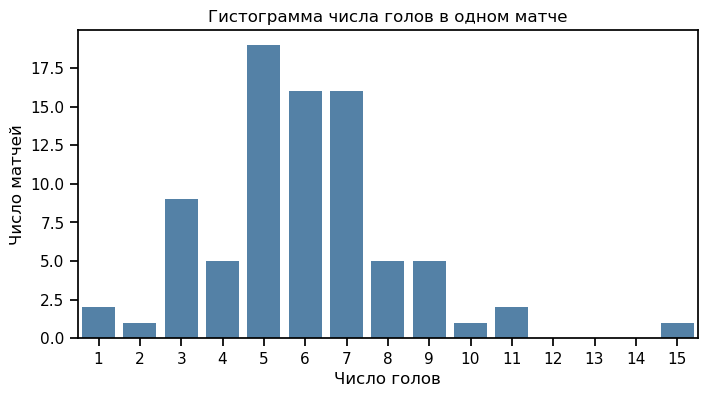

In [118]:
plt.figure(figsize=(8, 4))
sns.countplot(x=games['Total Score'], order=range(games['Total Score'].min(), games['Total Score'].max() + 1), color='steelblue')
plt.xlabel('Число голов')
plt.ylabel('Число матчей')
plt.title('Гистограмма числа голов в одном матче')
plt.show()

Вывод: Чаще всего в матче обе команды вместе забивали 5 голов. В большинстве игр было от 5 до 7 голов. Матчи с очень маленьким или очень большим количеством голов встречались редко.

6. Выведите список самых нерезультативных и самых результативных игр.

In [119]:
[gameInfo(gameId) for gameId in games[games['Total Score'] == games['Total Score'].min()].index]

['Montréal Canadiens - Tampa Bay Lightning (0 - 1, Final/OT, 2026-05-01)',
 'Philadelphia Flyers - Pittsburgh Penguins (1 - 0, Final/OT, 2026-04-29)']

In [120]:
[gameInfo(gameId) for gameId in games[games['Total Score'] == games['Total Score'].max()].index]

['Colorado Avalanche - Minnesota Wild (9 - 6, Final, 2026-05-03)']

С помощью min() и max() находим минимальное и максимальное количество голов за матч. Затем выбираем соответствующие игры и выводим информацию о них с помощью функции gameInfo(). Минимум составил 1 гол в двух матчах, максимум 15 голов в одном матче.

7. Для каждой игры сосчитайте, сколько игроков обеих команд в ней участвовало (поля Away Team’s Player on the Ice #1–Away Team’s Player on the Ice #6 и Away Team’s Player on the Ice #1–Away Team’s Player on the Ice #6, вратарей тоже считаем). Выведите список игр с наибольшим числом участвовавших игроков.

In [121]:
player_columns = events.columns[23:37]
player_counts = {}
for gameId, match in events.groupby('Game ID'):
    player_counts[gameId] = match[player_columns].stack().nunique()
games['Player Count'] = pd.Series(player_counts)
games['Game Info'] = [gameInfo(gameId) for gameId in games.index]
games[games['Player Count'] == games['Player Count'].max()][['Game Info', 'Player Count']]

,Game Info,Player Count
Game ID,,
2025030216,"Montréal Canadiens - Buffalo Sabres (3 - 8, Fi...",40


В каждом матче взяла столбцы с полевыми игроками и вратарями обеих команд. `stack()` собирает имена в один столбец, а `nunique()` считает каждого человека один раз, даже если он встречается во многих событиях. Затем находим игру с максимальным числом участников.

Получилось 40 игроков вместо 41 из примера. Мы считаем только уникальные имена и не учитываем пропуски (NaN), поскольку это не игроки.

8. Теперь рассмотрите броски в створ ворот и прошедшие мимо ворот. Для каждого броска сосчитайте расстояние до ворот. Для этого воспользуйтесь полями X Coordinate on the Ice Rink и Y Coordinate on the Ice Rink для событий типа shot-on-goal, goal (точные броски), missed-shot (неточные броски). Хоккейные ворота не являются точкой, а имеют длину 6 футов, поэтому расстояние сосчитайте до ближайшей точки створа ворот (координаты тоже в футах, в метры ничего преобразовывать не нужно). Координата $X$ ворот равняется 89 футов для ворот справа и −89 для ворот слева (см. рис. 2). Таким образом,

$$
d(x,y)=\begin{cases}
\sqrt{(x-X)^2+(y+3)^2}, & \text{если }y<-3,\\
|x-X|, & \text{если }-3\leq y\leq 3,\\
\sqrt{(x-X)^2+(y-3)^2}, & \text{если }y>3.
\end{cases}
$$

Кроме того, обратите внимание на поле Home Team’s Defending Side. Если оно равно left, то для бросков хозяев берите расстояние до правых ворот ($X=89$), а для бросков гостей — до левых ворот ($X=-89$). Если оно равно right, то наоборот. Понять, кто именно бросает, хозяева или гости, можно сравнив значения полей Team Making the Play с Home Team, например.

In [122]:
shots = events[events['Play Type'].isin(['shot-on-goal', 'goal', 'missed-shot'])].copy()
def shotLength(row):
    x = row['X Coordinate on the Ice Rink']
    y = row['Y Coordinate on the Ice Rink']
    home_shot = row['Team Making the Play'] == row['Home Team']
    if row["Home Team's Defending Side"] == 'left':
        X = 89 if home_shot else -89
    else:
        X = -89 if home_shot else 89
    if y < -3:
        return ((x - X)**2 + (y + 3)**2)**0.5
    if y > 3:
        return ((x - X)**2 + (y - 3)**2)**0.5
    return abs(x - X)
shots['Shot Length'] = shots.apply(shotLength, axis=1)
events.loc[shots.index, 'Shot Length'] = shots['Shot Length']

In [123]:
events[events['Play Type'].isin(['shot-on-goal', 'goal', 'missed-shot'])][['Game ID', 'Play Type', 'Shot Length']].round(3)

,Game ID,Play Type,Shot Length
7,2025030111,missed-shot,12.207
9,2025030111,missed-shot,12.000
12,2025030111,missed-shot,29.411
13,2025030111,shot-on-goal,62.169
19,2025030111,missed-shot,52.924
...,...,...,...
29695,2025030416,missed-shot,54.083
29696,2025030416,missed-shot,5.099
29704,2025030416,goal,46.239
29706,2025030416,missed-shot,60.926


Сначала выбираем все точные и неточные броски. Затем для каждого броска определяем расстояние до ворот соперника с учётом координат на площадке. Всего получилось 7 266 бросков.

9. Сравните распределение длины точных и неточных бросков. Для этого постройте гистограммы расстояния до ворот (построенное в предыдущем пункте) по группам точных и неточных бросков. Функция seaborn.displot() как раз годится для этого. Только надо сообразить, как вывести именно распределения, с учетом того, что размеры подвыборок точных и неточных бросков разные. Какой вывод можно сделать из данной гистограммы (пример на рис. 3)? Как вы думаете, почему наблюдается такой длинный хвост точных бросков со своей половины площадки?

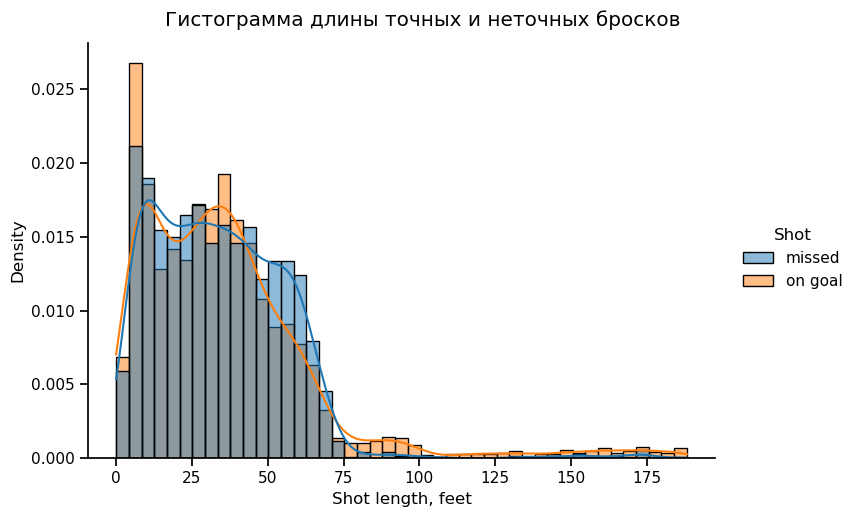

In [124]:
shots['Shot'] = np.where(shots['Play Type'] == 'missed-shot', 'missed', 'on goal')
g = sns.displot(data=shots, x='Shot Length', hue='Shot', bins=45, kde=True, stat='density', common_norm=False, height=5, aspect=1.5)
g.set_axis_labels('Shot length, feet', 'Density')
g.fig.suptitle('Гистограмма длины точных и неточных бросков', y=1.03)
plt.show()

Вывод: Большинство бросков совершается с расстояния до 70–75 футов. Распределения точных и неточных бросков в целом похожи, но среди точных встречаются броски с гораздо больших расстояний. Возможно, это связано с особенностями подсчёта бросков в хоккее, а также с попытками забить в пустые ворота.

10. Сосчитайте долю точных бросков среди всех незаблокированных бросков у каждой команды в каждой игре. Какой вывод можно сделать из найденной информации?

In [125]:
shots['On Goal'] = shots['Play Type'].isin(['shot-on-goal', 'goal']).astype(int)
shots['Goal'] = (shots['Play Type'] == 'goal').astype(int)
numshots = shots.groupby(['Game ID', 'Team Making the Play'])[['On Goal', 'Goal']].sum()
numshots['Share of Shots on Goal'] = numshots['On Goal'] / shots.groupby(['Game ID', 'Team Making the Play']).size()

In [126]:
numshots['Share of Shots on Goal'].round(3)

Game ID     Team Making the Play
2025030111  Boston Bruins           0.625
            Buffalo Sabres          0.679
2025030112  Boston Bruins           0.614
            Buffalo Sabres          0.636
2025030113  Boston Bruins           0.694
                                    ...  
2025030414  Vegas Golden Knights    0.583
2025030415  Carolina Hurricanes     0.558
            Vegas Golden Knights    0.510
2025030416  Carolina Hurricanes     0.639
            Vegas Golden Knights    0.595
Name: Share of Shots on Goal, Length: 164, dtype: float64

Для каждого матча и каждой команды считаем все незаблокированные броски, а также сколько из них попали в створ, включая голы. Затем делим число точных бросков на число всех незаблокированных. Так получается доля от 0 до 1.

Вывод: Доля точных бросков различается от игры к игре даже у одной команды. Это может зависеть от соперника, расстояния и позиции, с которой совершаются броски. При этом показатель отражает точность попадания в створ ворот, а не долю забитых шайб. Поэтому высокая точность не всегда означает больше голов.

11. Найдите и выведите по пять команд с самыми высокими и самыми низкими средними долями точных бросков за матч. Прокомментируйте результат.

In [127]:
avgnumshots = numshots.groupby('Team Making the Play')['Share of Shots on Goal'].mean()
avgnumshots.nlargest(5).round(3)

Team Making the Play
Edmonton Oilers        0.706
Philadelphia Flyers    0.684
Dallas Stars           0.670
Minnesota Wild         0.656
Colorado Avalanche     0.653
Name: Share of Shots on Goal, dtype: float64

In [128]:
avgnumshots.nsmallest(5).round(3)

Team Making the Play
Pittsburgh Penguins    0.554
Utah Mammoth           0.599
Carolina Hurricanes    0.615
Tampa Bay Lightning    0.626
Buffalo Sabres         0.626
Name: Share of Shots on Goal, dtype: float64

Вывод: Самая высокая средняя точность бросков у «Эдмонтона» (70,6%), а самая низкая у «Питтсбурга» (55,4%). Но высокая точность не обязательно означает больше голов, так как не каждый бросок в створ заканчивается голом.

12. Сосчитайте среднее число бросков в створ ворот и среднее число голов за игру для каждой из 16 команд-участниц плей-офф.

In [129]:
avgshots = numshots.groupby('Team Making the Play')[['On Goal', 'Goal']].mean()
avgshots = avgshots.rename(columns={'On Goal': 'Shot'})

In [130]:
avgshots.round(3)

,Shot,Goal
Team Making the Play,,
Anaheim Ducks,31.667,3.250
Boston Bruins,25.167,2.000
Buffalo Sabres,30.462,3.308
Carolina Hurricanes,31.632,3.474
Colorado Avalanche,32.154,3.385
Dallas Stars,31.000,2.500
Edmonton Oilers,28.333,3.500
Los Angeles Kings,25.250,1.250
Minnesota Wild,28.727,3.727


13. Теперь, используя результаты пункта 12, нарисуйте регрессионную диаграмму (функция seaborn.regplot()), показывающую, есть ли связь между средним числом бросков в створ ворот и средним числом забитых шайб (пример см. рис. 4). Как вы полагаете, связь видна или нет?

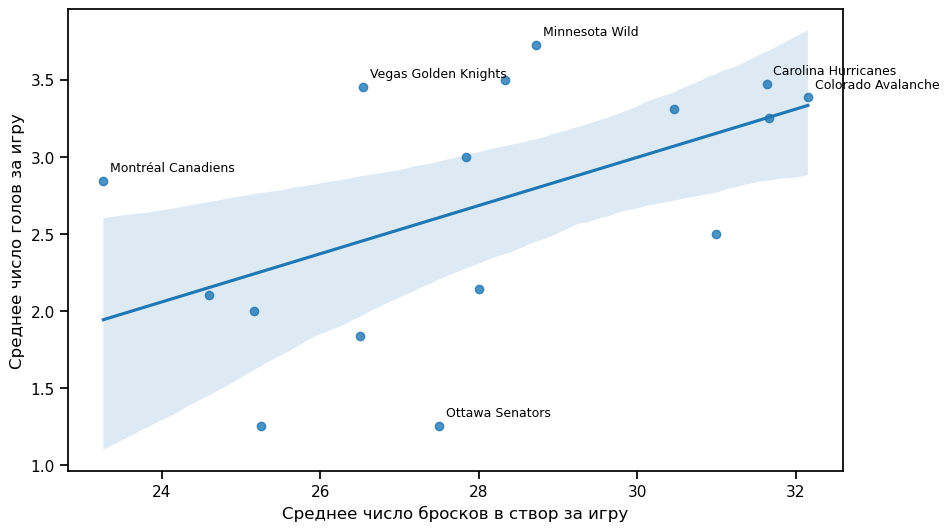

Коэффициент корреляции: 0.521


In [131]:
plt.figure(figsize=(10, 6))
sns.regplot(data=avgshots, x='Shot', y='Goal')
plt.xlabel('Среднее число бросков в створ за игру')
plt.ylabel('Среднее число голов за игру')
for team in ['Minnesota Wild', 'Vegas Golden Knights', 'Ottawa Senators', 'Montréal Canadiens', 'Carolina Hurricanes', 'Colorado Avalanche']:
    plt.annotate(team, (avgshots.loc[team, 'Shot'], avgshots.loc[team, 'Goal']), xytext=(5, 7), textcoords='offset points', fontsize=9)

plt.show()
print('Коэффициент корреляции:', round(avgshots['Shot'].corr(avgshots['Goal']), 3))

С помощью seaborn.regplot() построила график зависимости между средним числом бросков в створ и средним числом голов за матч.

Вывод: Положительная связь есть: команды, которые в среднем чаще бросают в створ, обычно забивают больше. Но зависимость не очень сильная (корреляция около 0,52), потому что важны также качество бросков и игра вратаря.

14. Найдите матч, в котором было совершено больше всего ударов по воротам (считайте все удары, включая промахи и заблокированные blocked-shot).

In [132]:
all_shot_types = ['shot-on-goal', 'goal', 'missed-shot', 'blocked-shot']
all_shots = events[events['Play Type'].isin(all_shot_types)]
shot_counts = all_shots.groupby('Game ID').size()
idxmax = shot_counts.idxmax()

In [133]:
gameInfo(idxmax)

'Carolina Hurricanes - Ottawa Senators (3 - 2, Final/2OT, 2026-04-20)'

In [134]:
print('Всего ударов:', shot_counts.max())

Всего ударов: 208


 Сначала выбираю все виды бросков, включая голы, промахи и заблокированные броски. Затем с помощью groupby() и size() считаю количество ударов в каждом матче, а idxmax() находит матч с наибольшим количеством ударов.

Больше всего ударов по воротам было в матче Carolina Hurricanes против Ottawa Senators (208 ударов). Игра закончилась со счётом 3:2 после двух овертаймов. Такое большое количество ударов можно объяснить в том числе большей продолжительностью матча. При подсчёте учитывались все удары, включая промахи и заблокированные броски.

15. Теперь нарисуйте диаграмму рассеивания (seaborn.scatterplot()), на которой изобразите точки, с которых наносились броски в матче, найденном в предыдущем пункте. Раскрасьте точки в соответствии с исходами ударов (переменная Play Type). Для рисования площадки можете воспользоваться кодом в файле, выложенном вместе с экзаменационным заданием на my.NES. Это файл rink.py, положите его в текущую директорию и можете пользоваться. 

Удары гостей нарисуйте, пожалуйста, как будто она бьет в левые от нас ворота, а удары хозяев — в правые. Для этого преобразуйте их координаты в нечетных периодах:

$$(x,y)\mapsto(-x,-y).$$

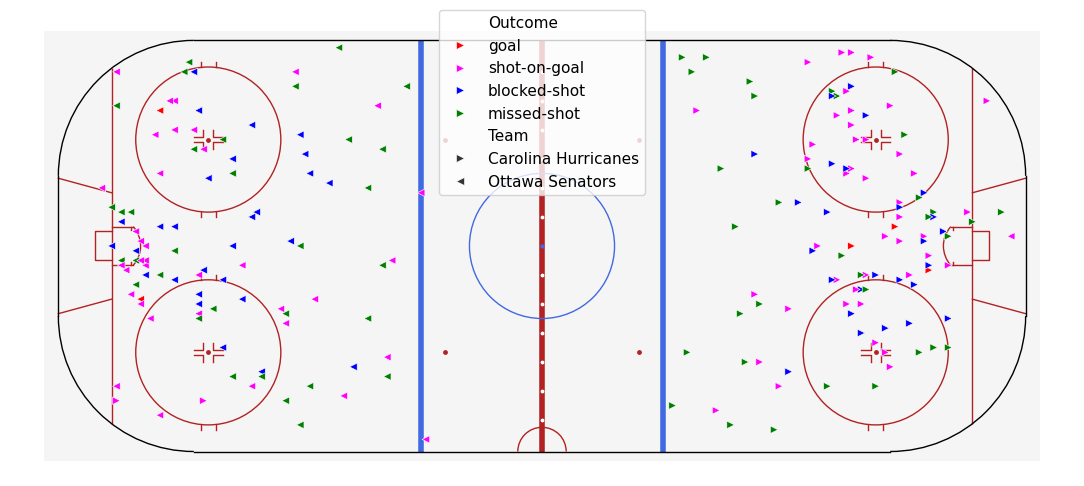

In [135]:
match_shots = all_shots[all_shots['Game ID'] == idxmax].copy()
odd_periods = match_shots['Period'] % 2 == 1
match_shots.loc[odd_periods, 'X Coordinate on the Ice Rink'] = -match_shots.loc[odd_periods, 'X Coordinate on the Ice Rink']
match_shots.loc[odd_periods, 'Y Coordinate on the Ice Rink'] = -match_shots.loc[odd_periods, 'Y Coordinate on the Ice Rink']
match_shots = match_shots.rename(columns={'Play Type': 'Outcome', 'Team Making the Play': 'Team'})
plt.figure(figsize=(11, 5))
plot_rink()
sns.scatterplot(data=match_shots, x='X Coordinate on the Ice Rink', y='Y Coordinate on the Ice Rink', hue='Outcome', hue_order=['goal', 'shot-on-goal', 'blocked-shot', 'missed-shot'], palette=['red', 'magenta', 'blue', 'green'], style='Team', markers={'Carolina Hurricanes': '>', 'Ottawa Senators': '<'}, s=30)
plt.axis('equal')
plt.axis('off')
plt.legend(loc='upper center', bbox_to_anchor=(0.5, 1.03))
plt.tight_layout()
plt.show()

16. Выведите список из десяти игроков, которые забили больше всех голов в плейофф (поле Player in the Event #1 для Play Type, равного goal).

In [136]:
goals = events[events['Play Type'] == 'goal']
goal_leaders = goals['Player in the Event #1'].value_counts()
goal_leaders.head(10)

Player in the Event #1
Brett Howden        14
Pavel Dorofeyev     12
Logan Stankoven     11
Mitch Marner        10
Jordan Staal         8
Nikolaj Ehlers       8
Nathan MacKinnon     7
Taylor Hall          7
Mark Stone           7
Jackson Blake        7
Name: count, dtype: int64

Оставляю только события `goal`, поскольку у них в `Player in the Event #1` указан автор шайбы. `value_counts()` подсчитывает голы каждого игрока. Больше всех забил Brett Howden, а именно 14 шайб.

17. Выведите список из десяти игроков, которые набрали больше всех голевых передач в плей-офф (поля Player in the Event #2 и Player in the Event #3 для Play Type, равного goal).

In [137]:
assists = pd.concat([goals['Player in the Event #2'], goals['Player in the Event #3']])
assist_leaders = assists.value_counts()
assist_leaders.head(10)

Jack Eichel        20
Mitch Marner       19
Jackson Blake      13
Lane Hutson        13
Taylor Hall        12
Martin Necas       12
Nick Suzuki        12
Shea Theodore      12
Quinn Hughes       11
Kirill Kaprizov    11
Name: count, dtype: int64

При каждом голе первый и второй ассистенты указаны в отдельных столбцах. Объединяю их в один список и считаю упоминания каждого игрока. Больше всех передач у Jack Eichel -20.

18. Выведите список из десяти игроков, которые набрали больше всего очков по системе гол плюс пас.

In [138]:
points = pd.concat([goals['Player in the Event #1'], goals['Player in the Event #2'], goals['Player in the Event #3']]).value_counts()
points.head(10)

Mitch Marner       29
Jack Eichel        22
Jackson Blake      20
Taylor Hall        19
Nikolaj Ehlers     18
Shea Theodore      18
Brett Howden       18
Lane Hutson        16
Pavel Dorofeyev    16
Nick Suzuki        16
Name: count, dtype: int64

По системе «гол плюс пас» за каждый гол или голевую передачу начисляется одно очко. Поэтому объединяем авторов голов и ассистентов и считаем, сколько раз встречается каждый игрок. Лидер- Mitch Marner с 29 очками.

19. Выведите список из десяти игроков, которые в среднем нанесли больше всего бросков в створ ворот за одну игру.

In [139]:
skater_columns = [column for column in events.columns if 'Player on the Ice #' in column]
player_games = events.set_index('Game ID')[skater_columns].stack().reset_index(name='Player')
games_per_player = player_games.groupby('Player')['Game ID'].nunique()
shots_per_player = events[events['Play Type'].isin(['shot-on-goal', 'goal'])]['Player in the Event #1'].value_counts()
average_player_shots = (shots_per_player / games_per_player).dropna()
average_player_shots.nlargest(10).round(3)

Jason Robertson     5.000
Dylan Guenther      4.500
Nikita Kucherov     4.429
Matt Boldy          4.364
Quinton Byfield     4.250
Darren Raddysh      4.000
Joel Eriksson Ek    4.000
Alex Laferriere     3.750
David Pastrnak      3.667
Nathan MacKinnon    3.615
dtype: float64

Сначала определяем количество матчей каждого игрока по его появлениям в столбцах состава на льду. Потом считаем броски в створ, включая голы, и делим на число матчей игрока. Так сравнение не зависит напрямую от того, сколько матчей сыграла его команда.

20. Выведите список из десяти игроков, которые в среднем провели больше всего силовых приемов за одну игру (поле Player in the Event #1 для Play Type, равного hit).

In [140]:
hits_per_player = events[events['Play Type'] == 'hit']['Player in the Event #1'].value_counts()
average_player_hits = (hits_per_player / games_per_player).dropna()
average_player_hits.nlargest(10).round(3)

Lawson Crouse         6.333
Alex Turcotte         6.000
Alexander Petrovic    6.000
Yakov Trenin          5.667
Dylan Cozens          5.500
Vasily Podkolzin      5.333
Carl Grundstrom       5.000
Ivan Barbashev        5.000
Marcus Foligno        5.000
Owen Tippett          4.833
dtype: float64

Силовые приёмы выбираем по типу события `hit`. Число таких событий каждого игрока делим на число сыгранных им матчей из предыдущего задания. По среднему числу силовых приёмов лидирует Lawson Crouse -6,333 за игру.

21. Выведите список всех вратарей, которые хотя бы в одном матче не пропустили ни одного гола (даже в тех случаях, когда играли не полную игру, а выходили на замену или наоборот были заменены).

In [143]:
zero_goalies = set()
for gameId, match in events.groupby('Game ID'):
    played = set(match[["Away Team's Goalie", "Home Team's Goalie"]].stack().dropna())
    scored = match[match['Play Type'] == 'goal'].copy()
    overtime = scored['Period'] > 3
    scored.loc[overtime, ["Away Team's Goalie", "Home Team's Goalie"]] = match[["Away Team's Goalie", "Home Team's Goalie"]].ffill().loc[overtime[overtime].index]
    conceded = set(scored.loc[scored['Team Making the Play'] == scored['Home Team'], "Away Team's Goalie"].dropna())
    conceded.update(scored.loc[scored['Team Making the Play'] == scored['Away Team'], "Home Team's Goalie"].dropna())
    zero_goalies.update(played - conceded)
sorted(zero_goalies)

['Andrei Vasilevskiy',
 'Brandon Bussi',
 'Dan Vladar',
 'Frederik Andersen',
 'Joonas Korpisalo',
 'Scott Wedgewood']

Для каждого матча находим всех вратарей, которые выходили на лёд, и проверяем, кто пропускал голы. Для голов в овертайме заполняем пропущенные данные о вратарях по предыдущим событиям. Затем выбираем тех, кто хотя бы в одном матче не пропустил ни одной шайбы. Всего получилось 6 вратарей.

22. Придумайте какой-нибудь содержательный вопрос, связанный с рассматриваемым набором данных, и ответьте на него.

**Мой вопрос:** Как часто команда, забившая первый гол, побеждала в матче?

In [144]:
first_goals = events[events['Play Type'] == 'goal'].groupby('Game ID')['Team Making the Play'].first()
games['First Goal Team'] = first_goals
games['Winner'] = games['Home Team']
games.loc[games['Away Score'] > games['Home Score'], 'Winner'] = games['Away Team']
first_goal_wins = (games['First Goal Team'] == games['Winner']).sum()
print('Побед после первого гола:', first_goal_wins)
print('Доля побед:', round(first_goal_wins / len(games) * 100, 1), '%')

Побед после первого гола: 56
Доля побед: 68.3 %


В 56 из 82 матчей (68,3%) выиграла команда, которая забила первой. Получается, что первый гол действительно может давать преимущество. Но это не гарантирует победу, так как в 26 матчах команда, пропустившая первой, всё равно смогла выиграть.

Сначала для каждого матча нахожу команду, которая забила первый гол. Затем определяю победителя по итоговому счёту и сравниваю команды, потом считаю количество матчей, в которых команда, забившая первой, победила, и находим их долю от общего числа игр.